# 01 — Historical inventory preprocessing and curation (Chapter 4)

**Aim:** Load and quality-check JMG original, JMG archive, COOLR and GFLD; preserve raw source observations; standardise an auditable common schema; identify genuine repeated source rows; conservatively screen cross-source event matches; and create an **event-candidate inventory** for later environmental extraction.

**Important definitions:** A *source observation* is a row contributed by one dataset. A *repeated native row* is a byte-for-byte equivalent combination of all native source fields. A *cross-source match candidate* is **not** a verified duplicate event. Neither an inside-boundary point nor a matching calendar date proves event identity. The archived JMG source CRS is still a hypothesis until original projection metadata or independent control points are available.

**Outputs:** `outputs/audits/inventory_catalogue.csv`, `duplicate_review.csv`, `inventory_summary.csv`; `data/processed/inventory/event_candidates.csv`; three useful figures. Older numbered audit CSVs are not inputs to this notebook. Run from the project root or `notebooks/` in VS Code. Dependencies: pandas, numpy, matplotlib, geopandas, shapely, pyproj, IPython.

**Normalization policy:** Coordinate and date *standardisation* happens here; numerical feature *scaling* must be fitted on training folds in Notebook 03, not on the full historical inventory. No target labels are created from unlabeled controls here.

**Revision:** Added independent-source-geometry control checks for archive raw RSO coordinates without increasing the number of output files.


In [1]:
from pathlib import Path
import hashlib
import json
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
# SciPy is used only to speed up pairwise duplicate screening in Section 10.
from IPython.display import display

# Find the root from either notebook working directory or project root.
candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT = next((p for p in candidates if (p / "data/raw/inventory").is_dir()), None)
if PROJECT is None:
    raise FileNotFoundError("Open VS Code in the FYP project directory and confirm data/raw/inventory exists.")
RAW = PROJECT / "data" / "raw" / "inventory"
AUDIT = PROJECT / "outputs" / "audits"
FIGURES = PROJECT / "outputs" / "figures"
AUDIT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT)

# Use the exact primary source filenames, avoiding ambiguous copies/validated variants.
paths = {
    "JMG_original": RAW / "JMG" / "JMG_Government_Raw_Landslide_Inventory.csv",
    "JMG_archive": RAW / "JMG_Archive" / "jmg_archive_2021_2022_raw.csv",
    "COOLR": RAW / "NASA_COOLR" / "coolr_malaysia_candidates.geojson",
    "GFLD": RAW / "GFLD" / "gfld_malaysia_validated.csv",
}
for name, path in paths.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing {name}: {path}")
print("All four primary files found.")


Project root: c:\landslide_fyp
All four primary files found.


## 1. Load immutable source files and audit native variables/observations

In [2]:
jmg = pd.read_csv(paths["JMG_original"], low_memory=False)
archive = pd.read_csv(paths["JMG_archive"], low_memory=False)
gfld = pd.read_csv(paths["GFLD"], low_memory=False)
with paths["COOLR"].open("r", encoding="utf-8") as f:
    coolr_geo = json.load(f)
if coolr_geo.get("type") != "FeatureCollection":
    raise ValueError("COOLR input is not a GeoJSON FeatureCollection")
coolr = pd.DataFrame([{
    **(feature.get("properties") or {}),
    "geometry_type": (feature.get("geometry") or {}).get("type"),
    "geometry_lon": ((feature.get("geometry") or {}).get("coordinates") or [None, None])[0],
    "geometry_lat": ((feature.get("geometry") or {}).get("coordinates") or [None, None])[1],
} for feature in coolr_geo["features"]])
sources = {"JMG_original": jmg, "JMG_archive": archive, "COOLR": coolr, "GFLD": gfld}
summary = pd.DataFrame([{
    "source": source, "rows": len(df), "columns": len(df.columns),
    "exact_full_row_repeats": int(df.duplicated().sum()),
    "source_file": paths[source].name,
    "sha256": hashlib.sha256(paths[source].read_bytes()).hexdigest(),
} for source, df in sources.items()])
display(summary[["source", "rows", "columns", "exact_full_row_repeats", "source_file"]])
print("Total source observations:", int(summary.rows.sum()))

schema = pd.DataFrame([{"source": src, "column": col, "dtype": str(df[col].dtype),
                         "non_null": int(df[col].notna().sum()),
                         "missing": int(df[col].isna().sum()),
                         "unique_non_null": int(df[col].nunique(dropna=True))}
                       for src, df in sources.items() for col in df.columns])
for name, df in sources.items():
    print(f"\n{name}: {len(df)} records — fields:")
    print(", ".join(df.columns))
    display(df.head(2))


,source,rows,columns,exact_full_row_repeats,source_file
0,JMG_original,52,41,0,JMG_Government_Raw_Landslide_Inventory.csv
1,JMG_archive,366,8,2,jmg_archive_2021_2022_raw.csv
2,COOLR,236,33,0,coolr_malaysia_candidates.geojson
3,GFLD,61,32,0,gfld_malaysia_validated.csv


Total source observations: 715

JMG_original: 52 records — fields:
SOURCE_FILE, Bil, Nama_Pegaw, Tindakan_d, Jabatan, Lain_Lain_, ID_Tanah_R, RSOx, RSOy, WGSe, WGSn, Daerah, Pihak_Berk, Negeri, Nama_Kampu, Nama_Jalan, Nama_Pemil, Hari, Tahun, Bulan, Jenis_Tana, Jenis_Keda, Punca_Tana, Geologi, Lebar__m_, Panjang__m, Kedalaman, Isipadu__m, Kos_Kerosa, Jenis_Kero, Bilangan_K, Bilangan_M, Guna_Tanah, Sumber, Catatan, Field1, Kod_Isipad, Keluasan, FID, ID__, Punca__


,SOURCE_FILE,Bil,Nama_Pegaw,Tindakan_d,Jabatan,Lain_Lain_,ID_Tanah_R,RSOx,RSOy,WGSe,...,Bilangan_M,Guna_Tanah,Sumber,Catatan,Field1,Kod_Isipad,Keluasan,FID,ID__,Punca__
0,uk_TANAH_RUNTUH_SEMENANJUNG_.shp,436.0,MUHAMMAD RAMZANEE MOHD NOH,Telah dipasang tarpaulin sheet oleh pihak tuan...,JMG Malaysia Selangor WP Kuala Lumpur,NaN,AU1318_M_05_SF_01,416717.63,343063.96,102.0,...,NaN,Perumahan,NaN,MTL,0.0,1.0,0.0,NaN,NaN,NaN
1,uk_TANAH_RUNTUH_SEMENANJUNG_.shp,395.0,MUHAMMAD RAMZANEE MOHD NOH,-,JMG Malaysia Selangor WP Kuala Lumpur,NaN,AU1318_N_01_L_01,417244.68,344799.69,102.0,...,NaN,Perumahan,NaN,MTL,0.0,1.0,66.0,NaN,NaN,NaN



JMG_archive: 366 records — fields:
Negeri, Daerah, Nama Kampung Atau Nama Taman Perumahan, RSOx, RSOy, Tarikh, Jenis Bencana, Jenis Tanah Runtuh


,Negeri,Daerah,Nama Kampung Atau Nama Taman Perumahan,RSOx,RSOy,Tarikh,Jenis Bencana,Jenis Tanah Runtuh
0,Johor,Kota Tinggi,"Jalan Gunung Panti, Taman Bukit Pelali",690284,155058,11/1/2021,Tanah Runtuh,Earth Slide (Translational)
1,Johor,Johor Bahru,"1/4 Jalan Bukit Kempas, Taman Bukit Kempas",633422,169151,11/1/2021,Tanah Runtuh,Earth Slide (Rotational)



COOLR: 236 records — fields:
objectid, source_name, source_link, event_id, event_date, event_time, event_title, event_description, location_description, location_accuracy, landslide_category, landslide_trigger, landslide_size, landslide_setting, fatality_count, injury_count, storm_name, photo_link, comments, event_import_source, event_import_id, latitude, longitude, country_name, country_code, admin_division_name, gazetteer_closest_point, gazetteer_distance, submitted_date, last_edited_date, geometry_type, geometry_lon, geometry_lat


,objectid,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description,location_accuracy,...,country_name,country_code,admin_division_name,gazetteer_closest_point,gazetteer_distance,submitted_date,last_edited_date,geometry_type,geometry_lon,geometry_lat
0,23,The Star,http://www.thestar.com.my/news/nation/2015/12/...,9083,1450483200000,NaN,Labuan,Incessant rains triggered landslide in four vi...,Labuan,25km,...,Malaysia,MY,Wilayah Persekutuan Labuan,Kpg Ganggarak,3.35,1469038799000,None,Point,115.2203,5.3149
1,82,KomunitiKini,https://web.archive.org/web/20101005042817/htt...,2510,1285702344000,20:00,Illegal excavation caused mudslide,"""Consistent heavy rain"" caused a mudslide in a...","Sun Moon city, Paya Terubong, Penang",5km,...,Malaysia,MY,Pulau Pinang,Georgetown,3.77,1516221145000,None,Point,100.2770,5.3630



GFLD: 61 records — fields:
FID, Latitude, Longitude, LandslideN, Country, Date, Day, Month, Year, Continent, Fatalities, Trigger_, Report_1, Source_1, Report_2, Source_2, Report_3, Source_3, Report_4, Source_4, Location_M, Precision_, Location_R, dataset, longitude, latitude, boundary_status, boundary_checked_against, state_standard, district_standard, state_method, district_method


,FID,Latitude,Longitude,LandslideN,Country,Date,Day,Month,Year,Continent,...,Location_R,dataset,longitude,latitude,boundary_status,boundary_checked_against,state_standard,district_standard,state_method,district_method
0,1013,5.372891,100.276044,5388,Malaysia,1505433600000,15,9,2017,S.E. Asia,...,"Paya Terubong, Penang",gfld,100.276044,5.372891,inside_or_on_boundary,mys_admin0(7).geojson (Admin-0),Pulau Pinang,NaN,state_name_in_location_text,unavailable_admin2_not_supplied
1,1014,3.231136,101.715989,212,Malaysia,1099612800000,5,11,2004,S.E. Asia,...,"Taman Harmonis, Gombak",gfld,101.715989,3.231136,inside_or_on_boundary,mys_admin0(7).geojson (Admin-0),NaN,NaN,unavailable,unavailable_admin2_not_supplied


## 2. Transform and validate dates without inventing missing days

In [3]:
malay_month = {"januari":1, "februari":2, "mac":3, "march":3, "april":4,
               "mei":5, "jun":6, "julai":7, "ogos":8, "september":9,
               "oktober":10, "november":11, "disember":12}

def jmg_original_date(row):
    year = pd.to_numeric(row.get("Tahun"), errors="coerce")
    day = pd.to_numeric(row.get("Hari"), errors="coerce")
    raw_month = str(row.get("Bulan", "")).strip().lower()
    month = malay_month.get(raw_month)
    if month is None:
        num = pd.to_numeric(raw_month, errors="coerce")
        month = int(num) if pd.notna(num) and num == int(num) and 1 <= num <= 12 else None
    if pd.isna(year): return (pd.NaT, "missing")
    if month is None: return (pd.NaT, "year_only")
    if pd.isna(day): return (pd.NaT, "month_year")
    try: return (pd.Timestamp(int(year), int(month), int(day)), "day")
    except (ValueError, TypeError): return (pd.NaT, "invalid_components")

# Strict full date parsing for archive; invalid dates are kept as invalid rather than repaired.
archive_text = archive["Tarikh"].astype("string").str.strip()
archive_date = pd.to_datetime(archive_text, format="%d/%m/%Y", errors="coerce")
archive_precision = np.where(archive_date.notna(), "day",
                     np.where(archive_text.str.fullmatch(r"\d{4}").fillna(False), "year_only",
                     np.where(archive_text.isna() | archive_text.eq(""), "missing", "unparsed_review")))
# Unix millisecond date fields; nulls/implausible values remain visible.
coolr_date = pd.to_datetime(pd.to_numeric(coolr["event_date"], errors="coerce"), unit="ms", utc=True, errors="coerce").dt.tz_localize(None).dt.normalize()
gfld_date = pd.to_datetime(pd.to_numeric(gfld["Date"], errors="coerce"), unit="ms", utc=True, errors="coerce").dt.tz_localize(None).dt.normalize()
jmg_dates = jmg.apply(jmg_original_date, axis=1)

def assemble_date_audit(source, df, dates, precision):
    dates = pd.Series(list(dates), index=df.index, dtype="datetime64[ns]")
    if isinstance(precision, str):
        precision = pd.Series(np.where(dates.notna(), "day", "missing_or_invalid"), index=df.index)
    return pd.DataFrame({"source":source, "source_row":df.index+1, "event_date_parsed":dates,
                         "date_precision":list(precision),
                         "year_for_chart": dates.dt.year})

jmg_audit = assemble_date_audit("JMG_original", jmg,
                                [x[0] for x in jmg_dates], [x[1] for x in jmg_dates])
archive_audit = assemble_date_audit("JMG_archive", archive, archive_date,
                   archive_precision)
coolr_audit = assemble_date_audit("COOLR", coolr, coolr_date,
                   np.where(coolr_date.notna(), "day_timestamp_field", "missing_or_invalid"))
gfld_audit = assemble_date_audit("GFLD", gfld, gfld_date,
                   np.where(gfld_date.notna(), "day_timestamp_field", "missing_or_invalid"))
date_audit = pd.concat([jmg_audit, archive_audit, coolr_audit, gfld_audit], ignore_index=True)
# Flag dates after snapshot/current run and pre-1900 for manual review; do not remove.
today = pd.Timestamp.today().normalize()
date_audit["date_plausibility"] = np.select([
    date_audit.event_date_parsed.isna(), date_audit.event_date_parsed > today,
    date_audit.event_date_parsed < pd.Timestamp("1900-01-01")],
    ["missing_or_partial", "future_review", "pre_1900_review"], default="chronologically_plausible")
display(pd.crosstab(date_audit.source, date_audit.date_precision))
display(pd.crosstab(date_audit.source, date_audit.date_plausibility))
print("Incomplete JMG original rows (source row positions):")
display(date_audit.query("source == 'JMG_original' and date_precision != 'day'"))


date_precision,day,day_timestamp_field,invalid_components,month_year,year_only
source,,,,,
COOLR,0,236,0,0,0
GFLD,0,61,0,0,0
JMG_archive,363,0,0,0,3
JMG_original,47,0,2,2,1


date_plausibility,chronologically_plausible,missing_or_partial
source,,
COOLR,236,0
GFLD,61,0
JMG_archive,363,3
JMG_original,47,5


Incomplete JMG original rows (source row positions):


,source,source_row,event_date_parsed,date_precision,year_for_chart,date_plausibility
40,JMG_original,41,NaT,month_year,NaN,missing_or_partial
44,JMG_original,45,NaT,year_only,NaN,missing_or_partial
45,JMG_original,46,NaT,invalid_components,NaN,missing_or_partial
46,JMG_original,47,NaT,invalid_components,NaN,missing_or_partial
51,JMG_original,52,NaT,month_year,NaN,missing_or_partial


## 3. Verify original JMG geometries and reconstruct geographic coordinates

The original JMG geometry is matched against projected X/Y and verified using each shapefile CRS. Archive positions use a clearly marked **provisional** EPSG:3375 assumption; internal consistency does not certify the original archive CRS.

The archive additionally undergoes a **raw projected-coordinate control check** against original JMG Peninsular shapefile points. An exact match is evidence supporting the assumed CRS for that location, not proof for every archive record; unchanged archive model-eligibility restrictions are deliberate.


In [4]:
# Requires: pip install geopandas pyproj shapely
import geopandas as gpd
from pyproj import Transformer
from shapely.geometry import Point
from zipfile import ZipFile
import tempfile

# Source shapefiles can be supplied as your existing extracted folder OR the original ZIP.
# ZIP is only read into a temporary folder during execution; your raw files remain unmodified.
spatial_root_candidates = [
    RAW / "Original_JMG_Spatial", RAW / "Original_JMG_Spatial" / "Original_JMG_Spatial",
    PROJECT / "data/raw/supporting_jmg/Original_JMG_Spatial",
]
spatial_root = next((p for p in spatial_root_candidates if p.is_dir() and list(p.rglob("*_TANAH_RUNTUH_*.shp"))), None)
spatial_zip_candidates = [
    RAW / "Original_JMG_Spatial.zip", RAW / "Original_JMG_Spatial" / "Original_JMG_Spatial.zip",
    PROJECT / "data/raw/supporting_jmg/Original_JMG_Spatial.zip",
]
spatial_zip = next((p for p in spatial_zip_candidates if p.is_file()), None)
temporary_jmg = None
if spatial_root is None and spatial_zip is not None:
    temporary_jmg = tempfile.TemporaryDirectory(prefix="jmg_geometry_")
    with ZipFile(spatial_zip) as z:
        # Extract only files from original source bundle to isolated temporary storage.
        z.extractall(temporary_jmg.name)
    spatial_root = Path(temporary_jmg.name)

shape_layers = {}
if spatial_root is not None:
    for shp in spatial_root.rglob("*.shp"):
        if shp.name in set(jmg.SOURCE_FILE.dropna().astype(str)):
            layer = gpd.read_file(shp)
            if layer.crs is None:
                print("Missing shapefile CRS — skip:", shp.name)
                continue
            shape_layers[shp.name] = layer
print("Original JMG shapefiles matched:", sorted(shape_layers))

# Source-specific geographical coordinates and evidence are stored separately.
geo_data = {}
for source, df in sources.items():
    geo_data[source] = pd.DataFrame({
        "longitude": pd.Series(np.nan, index=df.index, dtype=float),
        "latitude": pd.Series(np.nan, index=df.index, dtype=float),
        "crs_used": pd.Series("", index=df.index, dtype=str),
        "coordinate_method": pd.Series("", index=df.index, dtype=str),
        "source_geometry_match_m": pd.Series(np.nan, index=df.index, dtype=float),
        "coordinate_review": pd.Series("", index=df.index, dtype=str),
    })

# JMG original: use shapefile's stated CRS. Match each CSV row to its precise source geometry.
for idx, row in jmg.iterrows():
    source_file = str(row.get("SOURCE_FILE", ""))
    sx = pd.to_numeric(row.get("RSOx"), errors="coerce")
    sy = pd.to_numeric(row.get("RSOy"), errors="coerce")
    layer = shape_layers.get(source_file)
    if pd.isna(sx) or pd.isna(sy):
        geo_data["JMG_original"].loc[idx, "coordinate_review"] = "missing_projected_coordinates"
        continue
    if layer is None:
        geo_data["JMG_original"].loc[idx, "coordinate_review"] = "source_shapefile_unavailable"
        continue
    # Projected coordinates and source shapefile must agree: never use a nearest point
    # unless the match is unique and within tolerance.
    source_point = Point(float(sx), float(sy))
    distances = layer.geometry.distance(source_point)
    close = distances[distances <= 1.0]
    # When multiple source events share coordinates, disambiguate by original event ID.
    if len(close) > 1 and "ID_Tanah_R" in layer.columns and pd.notna(row.get("ID_Tanah_R")):
        key = str(row["ID_Tanah_R"]).strip()
        id_matches = [k for k in close.index if str(layer.loc[k, "ID_Tanah_R"]).strip() == key]
        if len(id_matches) == 1:
            close = close.loc[id_matches]
    if len(close) != 1:
        geo_data["JMG_original"].loc[idx, "coordinate_review"] = f"shapefile_coordinate_match_count_{len(close)}"
        continue
    match_idx = close.index[0]
    geom = layer.loc[match_idx, "geometry"]
    if geom is None or geom.is_empty or geom.geom_type != "Point":
        geo_data["JMG_original"].loc[idx, "coordinate_review"] = "matched_geometry_not_point"
        continue
    wgs_geom = gpd.GeoSeries([geom], crs=layer.crs).to_crs("EPSG:4326").iloc[0]
    geo_data["JMG_original"].loc[idx, ["longitude", "latitude", "crs_used", "coordinate_method", "source_geometry_match_m", "coordinate_review"]] = [
        wgs_geom.x, wgs_geom.y, str(layer.crs), "verified_original_shapefile_point", float(distances.loc[match_idx]), "source_geometry_matched"
    ]

# JMG archive: all supplied rows are from Peninsular states, but the CSV does not
# contain a .prj file. Apply the EPSG:3375 hypothesis and MARK it as provisional.
peninsular_states = {
    "johor", "kedah", "kelantan", "melaka", "negeri sembilan", "pahang", "perak",
    "perlis", "pulau pinang", "penang", "selangor", "terengganu",
    "w.p. kuala lumpur", "wp kuala lumpur", "w.p. putrajaya", "putrajaya", "kuala lumpur",
}
to_wgs_peninsular = Transformer.from_crs("EPSG:3375", "EPSG:4326", always_xy=True)
for idx, row in archive.iterrows():
    state = str(row.get("Negeri", "")).strip().casefold()
    x = pd.to_numeric(row.get("RSOx"), errors="coerce")
    y = pd.to_numeric(row.get("RSOy"), errors="coerce")
    if state not in peninsular_states or pd.isna(x) or pd.isna(y):
        geo_data["JMG_archive"].loc[idx, "coordinate_review"] = "unrecognised_state_or_missing_projected_pair"
        continue
    lon, lat = to_wgs_peninsular.transform(float(x), float(y))
    geo_data["JMG_archive"].loc[idx, ["longitude", "latitude", "crs_used", "coordinate_method", "coordinate_review"]] = [
        lon, lat, "EPSG:3375_assumed", "archive_RSO_transformation_provisional", "original_archive_CRS_unverified"
    ]

# Cross-check archive RSO X/Y directly against JMG original source coordinates.
# This check does NOT use the archive's transformed lon/lat to find matches,
# preventing a transformation error from creating artificial agreements.
# Only original points with a documented Peninsular CRS are valid controls.
original_control = jmg.loc[
    jmg.index.map(lambda i: geo_data["JMG_original"].at[i, "crs_used"] == "EPSG:3375")
].copy()
control_x = pd.to_numeric(original_control["RSOx"], errors="coerce")
control_y = pd.to_numeric(original_control["RSOy"], errors="coerce")
archive_x = pd.to_numeric(archive["RSOx"], errors="coerce")
archive_y = pd.to_numeric(archive["RSOy"], errors="coerce")
archive_control_checks = []
for idx in archive.index:
    ax, ay = archive_x.loc[idx], archive_y.loc[idx]
    if pd.isna(ax) or pd.isna(ay) or not len(original_control):
        archive_control_checks.append((idx, pd.NA, np.nan, np.nan, "no_valid_control"))
        continue
    dist = np.hypot(control_x.to_numpy(dtype=float) - float(ax),
                    control_y.to_numpy(dtype=float) - float(ay))
    near = np.flatnonzero(dist <= 2.0)
    if len(near) == 0:
        archive_control_checks.append((idx, pd.NA, float(np.nanmin(dist)), np.nan, "no_nearby_original_control"))
        continue
    if len(near) != 1:
        archive_control_checks.append((idx, pd.NA, float(np.nanmin(dist)), np.nan, "multiple_original_controls"))
        continue
    orig_idx = original_control.index[int(near[0])]
    # Compare independently derived WGS84 point from the original source shapefile.
    olon = geo_data["JMG_original"].at[orig_idx,"longitude"]
    olat = geo_data["JMG_original"].at[orig_idx,"latitude"]
    alon = geo_data["JMG_archive"].at[idx,"longitude"]
    alat = geo_data["JMG_archive"].at[idx,"latitude"]
    # Haversine distance with explicit coordinate ordering.
    from math import radians, sin, cos, sqrt, asin
    dlat, dlon = radians(olat-alat), radians(olon-alon)
    aa = sin(dlat/2)**2 + cos(radians(alat))*cos(radians(olat))*sin(dlon/2)**2
    wgs_distance = 2*6371008.8*asin(min(1.0,sqrt(aa)))
    archive_control_checks.append((idx, f"JMG_original:{orig_idx+1:05d}",
                                   float(dist[near[0]]), wgs_distance, "matched_original_control"))

archive_control_audit = pd.DataFrame(archive_control_checks,
    columns=["archive_row_index", "matched_original_uid", "raw_rso_distance_m",
             "independent_wgs_distance_m", "control_check_status"]).set_index("archive_row_index")
print("Archive CRS control checks (raw RSO coordinates; not an independent national CRS certification):")
display(archive_control_audit.control_check_status.value_counts().to_frame("archive_records"))
print("Unique original-control matches:",int(archive_control_audit.control_check_status.eq("matched_original_control").sum()))
print("Important: other archive records still retain their original_CRS_unverified flag.")

geo_data["COOLR"].loc[:, "longitude"] = pd.to_numeric(coolr["geometry_lon"], errors="coerce")
geo_data["COOLR"].loc[:, "latitude"] = pd.to_numeric(coolr["geometry_lat"], errors="coerce")
geo_data["COOLR"].loc[:, "crs_used"] = "CRS84"
geo_data["COOLR"].loc[:, "coordinate_method"] = "GeoJSON_point"
geo_data["COOLR"].loc[:, "coordinate_review"] = "source_geographic_point_pending_boundary_test"
geo_data["GFLD"].loc[:, "longitude"] = pd.to_numeric(gfld["longitude"], errors="coerce")
geo_data["GFLD"].loc[:, "latitude"] = pd.to_numeric(gfld["latitude"], errors="coerce")
geo_data["GFLD"].loc[:, "crs_used"] = "EPSG:4326"
geo_data["GFLD"].loc[:, "coordinate_method"] = "supplied_geographic_fields"
geo_data["GFLD"].loc[:, "coordinate_review"] = "source_geographic_point_pending_boundary_test"

# Reuse coordinate series in the rest of the notebook (including QC flags).
coords = {
    src: (g["longitude"], g["latitude"], "geographic_WGS84_from_source_specific_method", "see_coordinate_reconstruction_audit")
    for src, g in geo_data.items()
}
coordinate_summary = pd.DataFrame([{
    "source": src, "records": len(g),
    "geographic_pairs_present": int((g.longitude.notna() & g.latitude.notna()).sum()),
    "plausible_degree_pairs": int((g.longitude.between(-180,180) & g.latitude.between(-90,90)).sum()),
    "coordinate_methods": "; ".join(sorted(g.coordinate_method.unique())),
    "coordinate_reconstruction_issues": int((g.coordinate_review.str.contains("unavailable|missing|match_count|not_point|unrecognised", regex=True)).sum())
} for src, g in geo_data.items()])
display(coordinate_summary)

coordinate_detail = pd.concat([
    g.assign(source=src, source_row=g.index + 1) for src, g in geo_data.items()
], ignore_index=True)

# Inspect precision of the separate coordinate fields, without replacing shapefile geometry.
if {'WGSe','WGSn'}.issubset(jmg.columns):
    print('Original JMG separately stored WGS coordinate fields (informational only):')
    print('WGSe distinct:',jmg['WGSe'].nunique(dropna=True), 'WGSn distinct:',jmg['WGSn'].nunique(dropna=True))
    print('These coarse fields are not a suitable fine-scale accuracy reference.')


Original JMG shapefiles matched: ['ch_TANAH_RUNTUH_SEMENANJUNG_.shp', 'ipoh_TANAH_RUNTUH_SEMENANJUNG_.shp', 'kdsg_TANAH_RUNTUH_SABAH.shp', 'pp_TANAH_RUNTUH_SEMENANJUNG_.shp', 'uk_TANAH_RUNTUH_SEMENANJUNG_.shp']
Archive CRS control checks (raw RSO coordinates; not an independent national CRS certification):


,archive_records
control_check_status,
no_nearby_original_control,318
matched_original_control,46
multiple_original_controls,2


Unique original-control matches: 46
Important: other archive records still retain their original_CRS_unverified flag.


,source,records,geographic_pairs_present,plausible_degree_pairs,coordinate_methods,coordinate_reconstruction_issues
0,JMG_original,52,52,52,verified_original_shapefile_point,0
1,JMG_archive,366,366,366,archive_RSO_transformation_provisional,0
2,COOLR,236,236,236,GeoJSON_point,0
3,GFLD,61,61,61,supplied_geographic_fields,0


Original JMG separately stored WGS coordinate fields (informational only):
WGSe distinct: 8 WGSn distinct: 8
These coarse fields are not a suitable fine-scale accuracy reference.


## 4. Explore the native variables, missingness and year coverage

In [5]:
# Data dictionary: ALL native variables remain inspectable in source_*.csv
field_descriptions = {
    "RSOx": "Projected source easting (metres; CRS must be confirmed)",
    "RSOy": "Projected source northing (metres; CRS must be confirmed)",
    "WGSe": "Stored JMG longitude-like field; verify against shapefile",
    "WGSn": "Stored JMG latitude-like field; verify against shapefile",
    "Tarikh": "Original date string; may contain only a year",
    "Hari": "Original occurrence day component", "Bulan": "Original month component",
    "Tahun": "Original year component", "Negeri": "Reported state",
    "Daerah": "Reported district", "event_date": "COOLR Unix millisecond event date",
    "Date": "GFLD Unix millisecond event date", "geometry_lon": "COOLR GeoJSON longitude",
    "geometry_lat": "COOLR GeoJSON latitude", "longitude": "GFLD checked longitude",
    "latitude": "GFLD checked latitude", "Fatalities": "Reported fatalities, if available",
    "Precision_": "GFLD position precision attribute", "location_accuracy": "COOLR accuracy if present",
    "Jenis Bencana": "JMG archive disaster category", "Jenis Tanah Runtuh": "JMG archive landslide type"
}
dictionary = schema.copy()
dictionary["description_or_review_note"] = dictionary["column"].map(field_descriptions).fillna("Source-specific field; examine native source metadata before using as predictor")
dictionary["missing_pct"] = dictionary.apply(lambda r: round(100*r["missing"] / len(sources[r["source"]]), 1), axis=1)
print("Variables by source:")
display(dictionary.groupby("source").agg(native_variables=("column","count"), completely_empty_fields=("non_null",lambda x:int((x==0).sum()))))
print("Fields with highest missing proportions:")
display(dictionary.sort_values("missing_pct",ascending=False).groupby("source",group_keys=False).head(8)[["source","column","dtype","missing_pct","unique_non_null"]])
print("Example observations: one source record is not necessarily one unique landslide")
for src, df in sources.items():
    print(src, "—",len(df),"source observations")
    display(df.head(3).iloc[:,:min(9,len(df.columns))])


Variables by source:


,native_variables,completely_empty_fields
source,,
COOLR,33,1
GFLD,32,1
JMG_archive,8,0
JMG_original,41,0


Fields with highest missing proportions:


,source,column,dtype,missing_pct,unique_non_null
111,GFLD,district_standard,float64,100.0,0
78,COOLR,last_edited_date,object,100.0,0
65,COOLR,storm_name,str,99.6,1
5,JMG_original,Lain_Lain_,str,98.1,1
31,JMG_original,Bilangan_M,float64,98.1,1
39,JMG_original,ID__,str,96.2,2
33,JMG_original,Sumber,str,94.2,1
40,JMG_original,Punca__,str,94.2,3
67,COOLR,comments,str,93.2,16
16,JMG_original,Nama_Pemil,str,92.3,4


Example observations: one source record is not necessarily one unique landslide
JMG_original — 52 source observations


,SOURCE_FILE,Bil,Nama_Pegaw,Tindakan_d,Jabatan,Lain_Lain_,ID_Tanah_R,RSOx,RSOy
0,uk_TANAH_RUNTUH_SEMENANJUNG_.shp,436.0,MUHAMMAD RAMZANEE MOHD NOH,Telah dipasang tarpaulin sheet oleh pihak tuan...,JMG Malaysia Selangor WP Kuala Lumpur,NaN,AU1318_M_05_SF_01,416717.63,343063.96
1,uk_TANAH_RUNTUH_SEMENANJUNG_.shp,395.0,MUHAMMAD RAMZANEE MOHD NOH,-,JMG Malaysia Selangor WP Kuala Lumpur,NaN,AU1318_N_01_L_01,417244.68,344799.69
2,uk_TANAH_RUNTUH_SEMENANJUNG_.shp,445.0,MUHAMMAD RAMZANEE MOHD NOH,NaN,JMG Malaysia Selangor WP Kuala Lumpur,NaN,AU1322_M_02_SF_01,414215.01,348569.97


... (2 outputs left out)

COOLR — 236 source observations


,objectid,source_name,source_link,event_id,event_date,event_time,event_title,event_description,location_description
0,23,The Star,http://www.thestar.com.my/news/nation/2015/12/...,9083,1450483200000,NaN,Labuan,Incessant rains triggered landslide in four vi...,Labuan
1,82,KomunitiKini,https://web.archive.org/web/20101005042817/htt...,2510,1285702344000,20:00,Illegal excavation caused mudslide,"""Consistent heavy rain"" caused a mudslide in a...","Sun Moon city, Paya Terubong, Penang"
2,154,www.themalaymailonline.com,http://www.themalaymailonline.com/malaysia/art...,5500,1378857600000,NaN,"Penang Hill, Penang","Landslides remain a major threat in Penang, ca...","Penang Hill, Penang"


GFLD — 61 source observations


,FID,Latitude,Longitude,LandslideN,Country,Date,Day,Month,Year
0,1013,5.372891,100.276044,5388,Malaysia,1505433600000,15,9,2017
1,1014,3.231136,101.715989,212,Malaysia,1099612800000,5,11,2004
2,1015,5.683748,100.527763,3464,Malaysia,1356566400000,27,12,2012


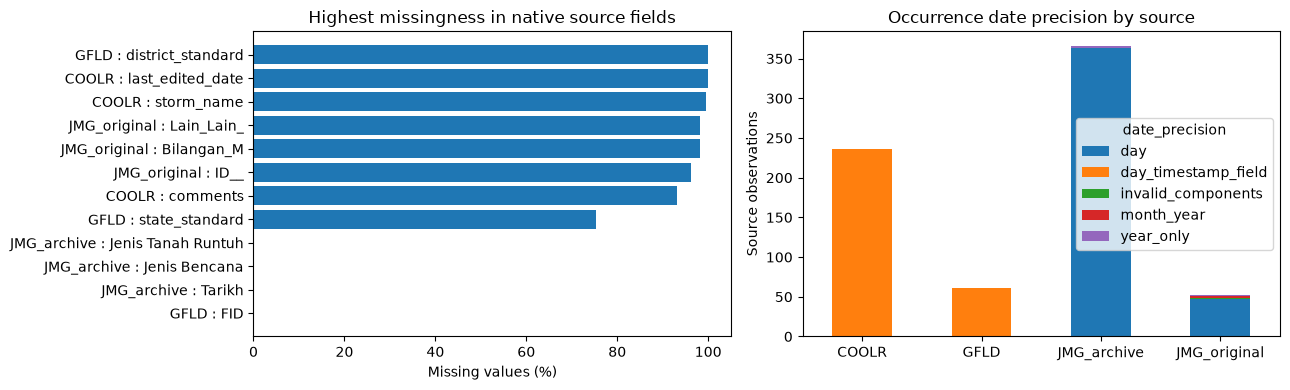

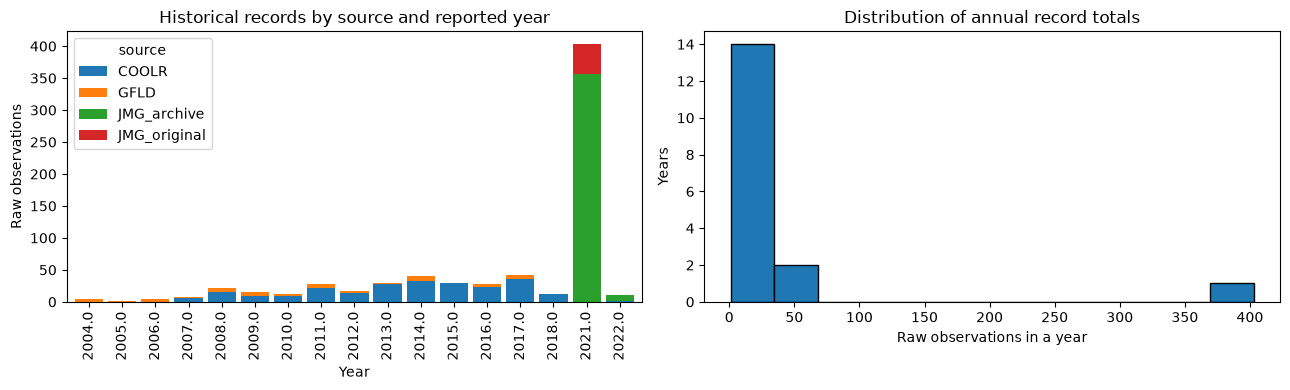

Annual source records including year-only dates:


source,COOLR,GFLD,JMG_archive,JMG_original
reported_year,,,,
2011.0,22,6,0,0
2012.0,14,3,0,0
2013.0,28,2,0,0
2014.0,33,7,0,0
2015.0,29,1,0,0
2016.0,23,5,0,0
2017.0,35,7,0,0
2018.0,12,0,0,0
2021.0,0,0,356,47


In [6]:
# Coverage including partial year-only observations, without inventing an event day.
year_reported = date_audit["year_for_chart"].copy()
arch_year_only = (date_audit["source"].eq("JMG_archive") & date_audit["date_precision"].eq("year_only"))
# The original source positions are 1-based, so lookup by source_row.
for ix in date_audit.index[arch_year_only]:
    year_reported.loc[ix] = int(archive_text.iloc[int(date_audit.loc[ix,"source_row"])-1])
annual_all = date_audit.assign(reported_year=year_reported).dropna(subset=["reported_year"]).groupby(["reported_year","source"]).size().unstack(fill_value=0)

fig, axs = plt.subplots(1,2,figsize=(13,4))
missing_top = dictionary.sort_values("missing_pct", ascending=False).groupby("source").head(3)
axs[0].barh(missing_top["source"]+" : "+missing_top["column"], missing_top["missing_pct"])
axs[0].set(xlabel="Missing values (%)",title="Highest missingness in native source fields")
axs[0].invert_yaxis()
precision_table = pd.crosstab(date_audit.source,date_audit.date_precision)
precision_table.plot.bar(stacked=True,ax=axs[1],rot=0)
axs[1].set(title="Occurrence date precision by source",ylabel="Source observations",xlabel="")
plt.tight_layout();plt.savefig(FIGURES / "missingness_date_precision.png", dpi=150, bbox_inches="tight");plt.show()

fig,axs = plt.subplots(1,2,figsize=(13,4))
annual_all.plot.bar(stacked=True,ax=axs[0],width=.85)
axs[0].set(title="Historical records by source and reported year",xlabel="Year",ylabel="Raw observations")
annual_all.sum(axis=1).plot.hist(ax=axs[1],bins=min(12,max(3,len(annual_all))),edgecolor="black")
axs[1].set(title="Distribution of annual record totals",xlabel="Raw observations in a year",ylabel="Years")
plt.tight_layout();plt.show()
print("Annual source records including year-only dates:")
display(annual_all.tail(10))


## 5. Audit unusual measurements, coordinates and dates (flag; do not clip/remove)

In [7]:
flags=[]
for source, df in sources.items():
    lon,lat,_,_ = coords[source]
    for i in df.index:
        lon_i,lat_i = lon.loc[i],lat.loc[i]
        d = date_audit.loc[(date_audit.source==source)&(date_audit.source_row==i+1)].iloc[0]
        issue=[]
        if pd.isna(lon_i) or pd.isna(lat_i):issue.append("geographic_coordinates_not_verified_or_missing")
        elif not (-180 <= lon_i <= 180 and -90 <= lat_i <= 90):issue.append("invalid_degree_range")
        elif not (99 <= lon_i <= 120 and 0 <= lat_i <= 8.5):issue.append("outside_broad_malaysia_envelope_review")
        if d.date_precision != "day" and d.date_precision != "day_timestamp_field":issue.append("non_day_date_or_unparsed")
        if d.date_plausibility in ("future_review","pre_1900_review"):issue.append(d.date_plausibility)
        flags.append({"source":source,"source_row":i+1,"quality_flags":"; ".join(issue),"flag_count":len(issue)})
quality_flags = pd.DataFrame(flags)
print("Records with one or more flags (NOT excluded):")
display(quality_flags.groupby("source").agg(total_records=("source_row","count"),flagged_records=("flag_count",lambda x:int((x>0).sum()))))

# Potential numeric distribution: descriptive only; no filtering, clipping or winsorising.
numeric_checks=[]
for src,df in sources.items():
    for col in (["Fatalities"] if src=="GFLD" else ["Lebar__m_","Panjang__m","Kedalaman","Isipadu__m"] if src=="JMG_original" else []):
        if col in df:
            x=pd.to_numeric(df[col],errors="coerce")
            numeric_checks.append({"source":src,"variable":col,"available":int(x.notna().sum()),"negative":int((x<0).sum()),"zero":int((x==0).sum()),"min":x.min(),"median":x.median(),"max":x.max()})
numeric_review=pd.DataFrame(numeric_checks)
display(numeric_review)
print("Nothing has been deleted or numerically normalised.")


Records with one or more flags (NOT excluded):


,total_records,flagged_records
source,,
COOLR,236,0
GFLD,61,0
JMG_archive,366,3
JMG_original,52,5


,source,variable,available,negative,zero,min,median,max
0,JMG_original,Lebar__m_,52,0,10,0.0,9.0,135.0
1,JMG_original,Panjang__m,52,0,10,0.0,10.5,774.0
2,JMG_original,Kedalaman,52,0,26,0.0,0.5,10.0
3,JMG_original,Isipadu__m,52,0,11,0.0,81.5,31450.0
4,GFLD,Fatalities,61,0,0,1.0,1.0,18.0


Nothing has been deleted or numerically normalised.


## 6. Standardise the observation catalogue, while retaining original fields in raw sources

In [ ]:
# Consistent column meanings; native data is preserved separately in input files.
standard=[]
for src,df in sources.items():
    matching = date_audit.loc[date_audit.source==src].set_index("source_row")
    lon,lat,_,_ = coords[src]
    for i,row in df.iterrows():
        d=matching.loc[i+1]
        if src=="JMG_original":
            sid=row.get("ID_Tanah_R"); state=row.get("Negeri"); district=row.get("Daerah")
            raw_date="/".join(str(row.get(c,"")) for c in ["Hari","Bulan","Tahun"])
            x,y=row.get("RSOx"),row.get("RSOy")
            outlon,outlat=lon.loc[i],lat.loc[i]  # matched source shapefile geometry
            location=row.get("Nama_Kampu")
        elif src=="JMG_archive":
            sid=None; state=row.get("Negeri"); district=row.get("Daerah")
            raw_date=row.get("Tarikh");x,y=row.get("RSOx"),row.get("RSOy")
            outlon,outlat=lon.loc[i],lat.loc[i]  # provisional CRS transform, flagged below
            location=row.get("Nama Kampung Atau Nama Taman Perumahan")
        elif src=="COOLR":
            sid=next((row.get(c) for c in ["OBJECTID","objectid","event_id","landslide_id"] if pd.notna(row.get(c))),None)
            state=next((row.get(c) for c in ["state","admin1"] if c in row),None)
            district=next((row.get(c) for c in ["district","admin2"] if c in row),None)
            raw_date=row.get("event_date");x=y=np.nan
            outlon,outlat=lon.loc[i],lat.loc[i];location=row.get("location_description")
        else:
            sid=row.get("FID");state=row.get("state_standard");district=row.get("district_standard")
            raw_date=row.get("Date");x=y=np.nan
            outlon,outlat=lon.loc[i],lat.loc[i];location=row.get("Location_M")
        standard.append({"record_uid":f"{src}:{i+1:05d}","source":src,"source_row":i+1,
            "source_identifier":sid,"original_date_value":raw_date,"event_date":d.event_date_parsed,
            "date_precision":d.date_precision,"reported_year":year_reported.loc[date_audit.index[(date_audit.source==src)&(date_audit.source_row==i+1)][0]],
            "state_raw":state,"district_raw":district,"location_raw":location,
            "longitude_candidate":outlon,"latitude_candidate":outlat,
            "projected_x_raw":x,"projected_y_raw":y,
            "coordinate_status":geo_data[src].loc[i,"coordinate_review"],
            "coordinate_method":geo_data[src].loc[i,"coordinate_method"],
            "coordinate_crs":geo_data[src].loc[i,"crs_used"],
            "source_geometry_match_m":geo_data[src].loc[i,"source_geometry_match_m"],
            "native_source_file":paths[src].name})
provisional = pd.DataFrame(standard).merge(quality_flags,on=["source","source_row"],how="left")
# Retain JMG archive raw-coordinate cross-check evidence in the main catalogue.
provisional["jmg_original_control_uid"] = pd.NA
provisional["jmg_raw_control_distance_m"] = np.nan
provisional["jmg_wgs_control_distance_m"] = np.nan
provisional["jmg_control_check_status"] = pd.NA
for idx, item in archive_control_audit.iterrows():
    catalogue_uid = f"JMG_archive:{idx+1:05d}"
    mask = provisional.record_uid.eq(catalogue_uid)
    provisional.loc[mask, "jmg_original_control_uid"] = item.matched_original_uidD
    provisional.loc[mask, "jmg_raw_control_distance_m"] = item.raw_rso_distance_m
    provisional.loc[mask, "jmg_wgs_control_distance_m"] = item.independent_wgs_distance_m
    provisional.loc[mask, "jmg_control_check_status"] = item.control_check_status

assert len(provisional)==sum(map(len,sources.values()))
assert provisional.record_uid.is_unique
assert provisional.loc[provisional.date_precision.eq("year_only"),"event_date"].isna().all()
display(provisional.groupby(["source","coordinate_status"]).size().rename("records").to_frame())
display(provisional.head())
print("Provisional catalogue:",len(provisional),"raw records. No cross-source deduplication or deletion.")


,,records
source,coordinate_status,
COOLR,source_geographic_point_pending_boundary_test,236
GFLD,source_geographic_point_pending_boundary_test,61
JMG_archive,original_archive_CRS_unverified,366
JMG_original,source_geometry_matched,52


,record_uid,source,source_row,source_identifier,original_date_value,event_date,date_precision,reported_year,state_raw,district_raw,...,coordinate_method,coordinate_crs,source_geometry_match_m,native_source_file,quality_flags,flag_count,jmg_original_control_uid,jmg_raw_control_distance_m,jmg_wgs_control_distance_m,jmg_control_check_status
0,JMG_original:00001,JMG_original,1,AU1318_M_05_SF_01,18.0/Disember/2021.0,2021-12-18,day,2021.0,W.P. Kuala Lumpur,Kuala Lumpur,...,verified_original_shapefile_point,EPSG:3375,0.0,JMG_Government_Raw_Landslide_Inventory.csv,,0,<NA>,NaN,NaN,<NA>
1,JMG_original:00002,JMG_original,2,AU1318_N_01_L_01,18.0/Disember/2021.0,2021-12-18,day,2021.0,Selangor,Ulu Langat,...,verified_original_shapefile_point,EPSG:3375,0.0,JMG_Government_Raw_Landslide_Inventory.csv,,0,<NA>,NaN,NaN,<NA>
2,JMG_original:00003,JMG_original,3,AU1322_M_02_SF_01,19.0/Disember/2021.0,2021-12-19,day,2021.0,W.P. Kuala Lumpur,Kuala Lumpur,...,verified_original_shapefile_point,EPSG:3375,0.0,JMG_Government_Raw_Landslide_Inventory.csv,,0,<NA>,NaN,NaN,<NA>
3,JMG_original:00004,JMG_original,4,AU1324_M_02_SF_01,18.0/Disember/2021.0,2021-12-18,day,2021.0,Selangor,Gombak,...,verified_original_shapefile_point,EPSG:3375,0.0,JMG_Government_Raw_Landslide_Inventory.csv,,0,<NA>,NaN,NaN,<NA>
4,JMG_original:00005,JMG_original,5,AU1324_M_03_SF_01,18.0/Disember/2021.0,2021-12-18,day,2021.0,Selangor,Ulu Langat,...,verified_original_shapefile_point,EPSG:3375,0.0,JMG_Government_Raw_Landslide_Inventory.csv,,0,<NA>,NaN,NaN,<NA>


Provisional catalogue: 715 raw records. No cross-source deduplication or deletion.


## 7. Validate coordinates against the Malaysia polygon

Malaysia boundary status by source:


malaysia_polygon_status,inside_or_on_boundary,outside_boundary_review
source,,
COOLR,236,0
GFLD,60,1
JMG_archive,364,2
JMG_original,52,0


Coordinate evidence / verification by source:


geographic_verification_level,archive_CRS_assumed_requires_confirmation,source_GeoJSON_point,source_geographic_fields,source_shapefile_geometry_matched
source,,,,
COOLR,0,236,0,0
GFLD,0,0,61,0
JMG_archive,366,0,0,0
JMG_original,0,0,0,52


Outside-boundary candidates for manual inspection:


,record_uid,source,source_row,state_raw,district_raw,projected_x_raw,projected_y_raw,longitude_candidate,latitude_candidate,coordinate_crs,coordinate_method,coordinate_status,source_geometry_match_m,malaysia_polygon_status,geographic_verification_level
146,JMG_archive:00095,JMG_archive,95,Kedah,Yan,264296.0,646233.0,100.363593,5.837018,EPSG:3375_assumed,archive_RSO_transformation_provisional,original_archive_CRS_unverified,NaN,outside_boundary_review,archive_CRS_assumed_requires_confirmation
395,JMG_archive:00344,JMG_archive,344,Terengganu,Kuala Terengganu,571747.0,590509.0,103.140010,5.339985,EPSG:3375_assumed,archive_RSO_transformation_provisional,original_archive_CRS_unverified,NaN,outside_boundary_review,archive_CRS_assumed_requires_confirmation
672,GFLD:00019,GFLD,19,NaN,NaN,NaN,NaN,116.120558,6.118188,EPSG:4326,supplied_geographic_fields,source_geographic_point_pending_boundary_test,NaN,outside_boundary_review,source_geographic_fields


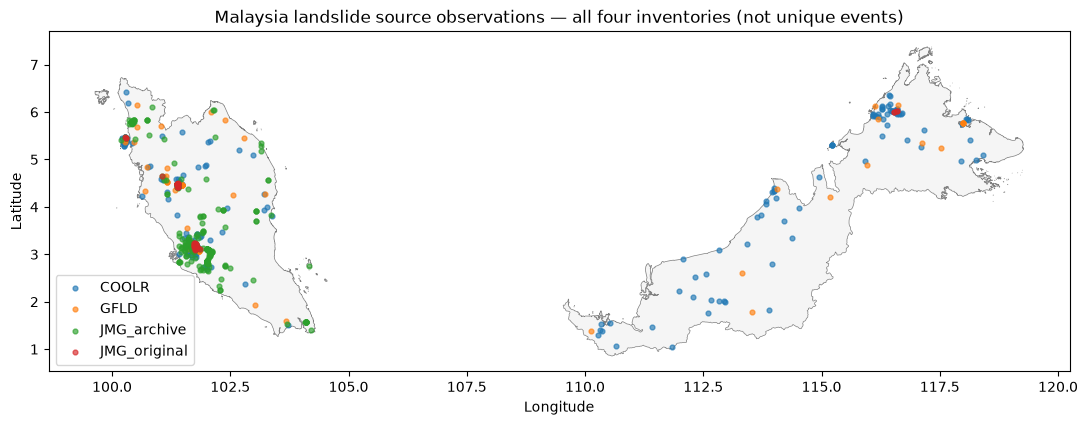

Important: archive projection is provisional; inside a national polygon does NOT confirm its original CRS.


In [9]:
# Exact polygon check, not rectangular Malaysia latitude/longitude bounds.
boundary_candidates = [
    PROJECT / "data/raw/references/boundary/mys_admin0.geojson",
    PROJECT / "data/raw/reference/boundary/mys_admin0.geojson",
]
boundary_path = next((p for p in boundary_candidates if p.is_file()), None)
if boundary_path is None:
    raise FileNotFoundError("Malaysia national boundary GeoJSON not found in data/raw/references/boundary")
boundary = gpd.read_file(boundary_path)
if boundary.crs is None:
    raise ValueError("Boundary has no CRS — check source before geographic validation")
boundary = boundary.to_crs("EPSG:4326")
malaysia_polygon = boundary.geometry.union_all() if hasattr(boundary.geometry, "union_all") else boundary.unary_union

provisional["malaysia_polygon_status"] = "not_checked_no_geographic_point"
valid = (provisional.longitude_candidate.between(-180,180) & provisional.latitude_candidate.between(-90,90))
points = gpd.GeoSeries(
    gpd.points_from_xy(provisional.loc[valid,"longitude_candidate"], provisional.loc[valid,"latitude_candidate"]),
    index=provisional.index[valid], crs="EPSG:4326"
)
provisional.loc[valid,"malaysia_polygon_status"] = np.where(
    points.intersects(malaysia_polygon), "inside_or_on_boundary", "outside_boundary_review"
)
provisional["geographic_verification_level"] = np.select([
    provisional.coordinate_method.eq("verified_original_shapefile_point"),
    provisional.coordinate_method.eq("archive_RSO_transformation_provisional"),
    provisional.coordinate_method.eq("GeoJSON_point"),
    provisional.coordinate_method.eq("supplied_geographic_fields"),
], ["source_shapefile_geometry_matched", "archive_CRS_assumed_requires_confirmation",
    "source_GeoJSON_point", "source_geographic_fields"], default="not_verified")

review = provisional[["record_uid","source","source_row","state_raw","district_raw",
    "projected_x_raw","projected_y_raw","longitude_candidate","latitude_candidate",
    "coordinate_crs","coordinate_method","coordinate_status","source_geometry_match_m",
    "malaysia_polygon_status","geographic_verification_level"]].copy()
print("Malaysia boundary status by source:")
display(pd.crosstab(provisional.source, provisional.malaysia_polygon_status))
print("Coordinate evidence / verification by source:")
display(pd.crosstab(provisional.source, provisional.geographic_verification_level))
print("Outside-boundary candidates for manual inspection:")
display(review.loc[review.malaysia_polygon_status.eq("outside_boundary_review")])

ax = boundary.plot(figsize=(11,7),color="whitesmoke",edgecolor="gray",linewidth=.5)
for src,g in provisional.loc[valid].groupby("source"):
    ax.scatter(g.longitude_candidate,g.latitude_candidate,s=12,label=src,alpha=.65)
ax.set(xlabel="Longitude", ylabel="Latitude", title="Malaysia landslide source observations — all four inventories (not unique events)")
ax.legend(loc="best")
plt.tight_layout()

plt.savefig(FIGURES / "inventory_locations.png", dpi=150, bbox_inches="tight")
plt.show()
print("Important: archive projection is provisional; inside a national polygon does NOT confirm its original CRS.")
if temporary_jmg is not None:
    temporary_jmg.cleanup()


## 8. Document geographic-review flags

In [10]:
# Integrate geographic review flags while preserving every raw source observation.
# Run this cell after all earlier notebook cells. Existing stage outputs stay intact.

def append_flag(existing, new_flag):
    parts = [] if pd.isna(existing) or str(existing).strip() == "" else str(existing).split("|")
    if new_flag not in parts:
        parts.append(new_flag)
    return "|".join(parts)

outside_mask = provisional["malaysia_polygon_status"].eq("outside_boundary_review")
archive_mask = provisional["coordinate_method"].eq("archive_RSO_transformation_provisional")
for index in provisional.index[outside_mask]:
    provisional.at[index, "quality_flags"] = append_flag(provisional.at[index, "quality_flags"], "outside_boundary_requires_review")
for index in provisional.index[archive_mask]:
    provisional.at[index, "quality_flags"] = append_flag(provisional.at[index, "quality_flags"], "archive_CRS_assumed_unverified")
provisional["flag_count"] = provisional["quality_flags"].fillna("").apply(
    lambda v: len([s for s in v.split("|") if s])
)
provisional["geographic_review_required"] = outside_mask | archive_mask
# Geographic review is independent from event-date precision and source deduplication.
provisional["coordinate_usable_for_preliminary_spatial_review"] = (
    provisional["longitude_candidate"].between(-180, 180)
    & provisional["latitude_candidate"].between(-90, 90)
)

geographic_cases = provisional.loc[outside_mask, [
    "record_uid", "source", "source_row", "event_date", "date_precision",
    "state_raw", "district_raw", "location_raw", "longitude_candidate",
    "latitude_candidate", "coordinate_method", "coordinate_crs",
    "malaysia_polygon_status", "geographic_verification_level", "quality_flags"
]].copy()
geographic_cases["review_decision"] = "pending_manual_review"
geographic_cases["possible_explanation"] = "coastline_or_positional_uncertainty_or_source_error"

geographic_summary = provisional.groupby("source").agg(
    observations=("record_uid", "size"),
    coordinate_available=("coordinate_usable_for_preliminary_spatial_review", "sum"),
    inside_boundary=("malaysia_polygon_status", lambda s: int((s == "inside_or_on_boundary").sum())),
    outside_review=("malaysia_polygon_status", lambda s: int((s == "outside_boundary_review").sum())),
    archive_crs_assumption=("coordinate_method", lambda s: int((s == "archive_RSO_transformation_provisional").sum())),
    geographic_review_required=("geographic_review_required", "sum"),
).reset_index()

assert len(provisional) == sum(len(df) for df in sources.values()) == 715
assert provisional["record_uid"].is_unique
assert provisional["coordinate_usable_for_preliminary_spatial_review"].all()
assert int(outside_mask.sum()) == len(geographic_cases)
assert int(archive_mask.sum()) == len(archive)
assert geographic_summary.observations.sum() == 715
assert geographic_summary.inside_boundary.sum() + geographic_summary.outside_review.sum() == 715

print("Geographic QA summary — source observations, not verified unique landslides")
display(geographic_summary)
print("Outside-boundary cases: manual investigation required; no records removed")
display(geographic_cases)
print("Archive source CRS: EPSG:3375 is a working assumption, NOT independently confirmed")
print("Geographic validation complete in memory; consolidated exports are written at the end.")


Geographic QA summary — source observations, not verified unique landslides


,source,observations,coordinate_available,inside_boundary,outside_review,archive_crs_assumption,geographic_review_required
0,COOLR,236,236,236,0,0,0
1,GFLD,61,61,60,1,0,1
2,JMG_archive,366,366,364,2,366,366
3,JMG_original,52,52,52,0,0,0


Outside-boundary cases: manual investigation required; no records removed


,record_uid,source,source_row,event_date,date_precision,state_raw,district_raw,location_raw,longitude_candidate,latitude_candidate,coordinate_method,coordinate_crs,malaysia_polygon_status,geographic_verification_level,quality_flags,review_decision,possible_explanation
146,JMG_archive:00095,JMG_archive,95,2021-09-19,day,Kedah,Yan,Tanjung Jaga,100.363593,5.837018,archive_RSO_transformation_provisional,EPSG:3375_assumed,outside_boundary_review,archive_CRS_assumed_requires_confirmation,outside_boundary_requires_review|archive_CRS_a...,pending_manual_review,coastline_or_positional_uncertainty_or_source_...
395,JMG_archive:00344,JMG_archive,344,2021-08-02,day,Terengganu,Kuala Terengganu,Jambatan Angkat Terengganu,103.140010,5.339985,archive_RSO_transformation_provisional,EPSG:3375_assumed,outside_boundary_review,archive_CRS_assumed_requires_confirmation,outside_boundary_requires_review|archive_CRS_a...,pending_manual_review,coastline_or_positional_uncertainty_or_source_...
672,GFLD:00019,GFLD,19,2006-06-26,day_timestamp_field,NaN,NaN,Karambunai,116.120558,6.118188,supplied_geographic_fields,EPSG:4326,outside_boundary_review,source_geographic_fields,outside_boundary_requires_review,pending_manual_review,coastline_or_positional_uncertainty_or_source_...


Archive source CRS: EPSG:3375 is a working assumption, NOT independently confirmed
Geographic validation complete in memory; consolidated exports are written at the end.


## 9. Review source-level records, dates and geographic coverage

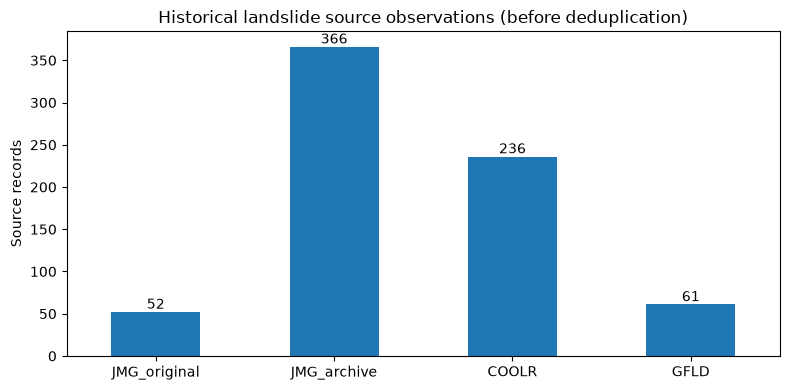

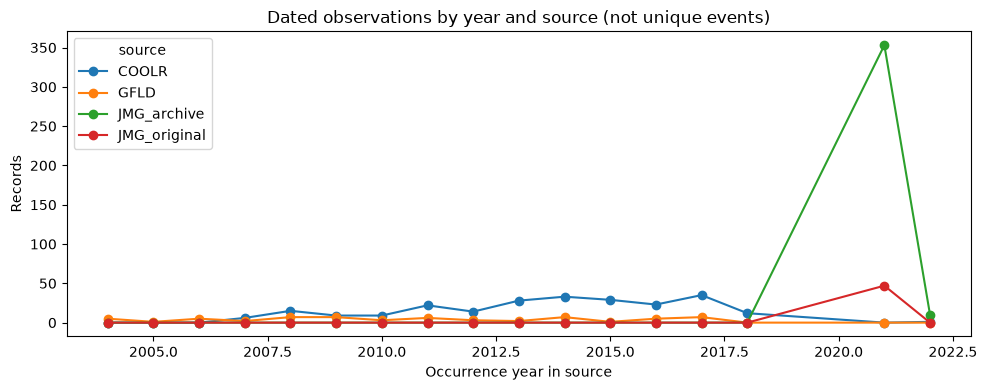


JMG_original: 10 fields with highest missing counts


,missing_rows
Lain_Lain_,51
Bilangan_M,51
ID__,50
Sumber,49
Punca__,49
Nama_Pemil,48
FID,47
Tindakan_d,31
Jenis_Kero,22
Catatan,20



JMG_archive: 10 fields with highest missing counts


,missing_rows
Negeri,0
Daerah,0
Nama Kampung Atau Nama Taman Perumahan,0
RSOx,0
RSOy,0
Tarikh,0
Jenis Bencana,0
Jenis Tanah Runtuh,0



COOLR: 10 fields with highest missing counts


,missing_rows
last_edited_date,236
storm_name,235
comments,220
photo_link,171
injury_count,106
event_time,99
event_import_id,66
fatality_count,42
location_description,2
objectid,0



GFLD: 10 fields with highest missing counts


,missing_rows
district_standard,61
state_standard,46
FID,0
Latitude,0
Country,0
Date,0
Longitude,0
LandslideN,0
Year,0
Continent,0


In [11]:
ax=summary.plot.bar(x="source",y="rows",legend=False,figsize=(8,4),rot=0)
ax.set(title="Historical landslide source observations (before deduplication)",ylabel="Source records",xlabel="")
for c in ax.containers: ax.bar_label(c)
plt.tight_layout();plt.savefig(FIGURES / "source_counts.png", dpi=150);plt.show()

annual=(date_audit.dropna(subset=["year_for_chart"])
        .groupby(["year_for_chart","source"]).size().unstack(fill_value=0).sort_index())
ax=annual.plot(figsize=(10,4),marker="o",linewidth=1.5)
ax.set(title="Dated observations by year and source (not unique events)",xlabel="Occurrence year in source",ylabel="Records")
plt.tight_layout();plt.show()

# Missingness heat map: per-source variable availability, not directly comparable semantics.
for name,df in sources.items():
    print(f"\n{name}: 10 fields with highest missing counts")
    display(df.isna().sum().sort_values(ascending=False).head(10).rename("missing_rows").to_frame())


## 10. Cross-source duplicate candidate screening

Candidates are generated from geographic proximity and compatible dates, but **not automatically merged**. Within a source, distinct rows with different positions or descriptions can be separate landslides. Native identical-row pairs are reproducibly confirmed as redundant source copies. Cross-source matches remain unconfirmed because neither independently assigned event IDs nor the archive's original projection metadata currently establish event identity.

In [12]:
from itertools import combinations
from math import radians, sin, cos, asin, sqrt
from difflib import SequenceMatcher
from collections import Counter


def distance_m(lon1, lat1, lon2, lat2):
    p1, p2 = radians(float(lat1)), radians(float(lat2))
    dp, dl = p2 - p1, radians(float(lon2) - float(lon1))
    q = sin(dp/2)**2 + cos(p1)*cos(p2)*sin(dl/2)**2
    return 6371008.8 * 2 * asin(min(1, sqrt(q)))


def location_tokens(value):
    if pd.isna(value):
        return set()
    text = re.sub(r'[^a-z0-9]+', ' ', str(value).casefold()).strip()
    generic = {'jalan', 'jln', 'kg', 'kampung', 'taman', 'no', 'lot', 'di', 'the', 'near',
               'bukit', 'sungai', 'sg', 'lorong', 'km', 'area', 'landslide'}
    return {w for w in text.split() if len(w) > 2 and w not in generic}


def place_support(a, b):
    ta, tb = location_tokens(a), location_tokens(b)
    if not ta or not tb:
        return 'not_available', 0.0
    similarity = len(ta & tb) / len(ta | tb)
    # A shared rare place term or high word-set overlap is supporting evidence,
    # not proof that different slope failures are the same event.
    if similarity >= 0.6:
        return 'strong', round(similarity, 3)
    if similarity > 0:
        return 'partial', round(similarity, 3)
    return 'different', 0.0

s = provisional.reset_index(drop=True).copy()
s['event_date'] = pd.to_datetime(s.event_date, errors='coerce')
valid_s = s.longitude_candidate.notna() & s.latitude_candidate.notna()
exact_native_uids = set()
pairs = []

# KD-tree prefilter: any pair within both ±0.005° axis windows has
# Euclidean separation <= sqrt(2)*0.005 < 0.008 degrees. Thus this safe
# superset preserves ALL previously compared candidate pairs, but avoids
# ~255,000 unnecessary Python pairwise iterations.
from scipy.spatial import cKDTree
valid_rows=np.flatnonzero(valid_s.to_numpy())
xy=s.loc[valid_s,['longitude_candidate','latitude_candidate']].to_numpy(dtype=float)
spatial_tree=cKDTree(xy)
near_pairs=sorted((int(valid_rows[i]),int(valid_rows[j]))
                  for i,j in spatial_tree.query_pairs(r=0.008))
print('Spatial candidate pairs to inspect:',len(near_pairs))
for i,j in near_pairs:
    a, b = s.iloc[i], s.iloc[j]
    if not (valid_s.iat[i] and valid_s.iat[j]):
        continue
    if abs(float(a.latitude_candidate)-float(b.latitude_candidate)) > .005 or abs(float(a.longitude_candidate)-float(b.longitude_candidate)) > .005:
        continue
    metres = distance_m(a.longitude_candidate, a.latitude_candidate,
                        b.longitude_candidate, b.latitude_candidate)
    if metres > 500:
        continue
    same_source = a.source == b.source
    exact_native = False
    if same_source:
        aa = sources[a.source].iloc[int(a.source_row)-1]
        bb = sources[b.source].iloc[int(b.source_row)-1]
        exact_native = bool(aa.equals(bb))
    full_a = a.date_precision in ('day', 'day_timestamp_field') and pd.notna(a.event_date)
    full_b = b.date_precision in ('day', 'day_timestamp_field') and pd.notna(b.event_date)
    day_difference = int(abs((a.event_date-b.event_date).days)) if full_a and full_b else np.nan
    same_day = bool(pd.notna(day_difference) and day_difference == 0)
    same_year = pd.notna(a.reported_year) and pd.notna(b.reported_year) and int(a.reported_year) == int(b.reported_year)
    projected_distance = np.nan
    same_projected = False
    if (a.source in ('JMG_original','JMG_archive') and b.source in ('JMG_original','JMG_archive')
        and pd.notna(a.projected_x_raw) and pd.notna(a.projected_y_raw)
        and pd.notna(b.projected_x_raw) and pd.notna(b.projected_y_raw)):
        projected_distance = float(np.hypot(float(a.projected_x_raw)-float(b.projected_x_raw),
                                            float(a.projected_y_raw)-float(b.projected_y_raw)))
        same_projected = projected_distance <= 2
    place_level, place_score = place_support(a.location_raw,b.location_raw)
    state_consistent = (str(a.state_raw).strip().casefold()==str(b.state_raw).strip().casefold()) if pd.notna(a.state_raw) and pd.notna(b.state_raw) else None

    # Discovery, not event merging. Same-source matching is deliberately narrow;
    # keep several nearby archive observations separate unless native rows are identical.
    if same_source:
        if not exact_native and not (same_day and metres <= 25 and place_level in ('strong','partial')):
            continue
    else:
        if not ((same_day and metres<=500) or ((not full_a or not full_b) and same_year and metres<=100)):
            continue

    if exact_native:
        evidence = 'identical_native_row'
        decision = 'confirmed_repeated_source_row'
        explanation = 'Every native field identical. Retain both source rows; one repeat may later be suppressed in the event table.'
        exact_native_uids.update((a.record_uid,b.record_uid))
    elif same_source:
        evidence = 'same_source_same_day_local_cluster'
        decision = 'separate_events_possible_review'
        explanation = 'Distinct native rows; proximity/date/place can describe multiple failures. Never auto-merge.'
    elif same_day and same_projected and place_level in ('strong','partial') and state_consistent is not False:
        evidence = 'cross_source_same_projected_point_day_place'
        decision = 'strong_candidate_manual_confirmation'
        explanation = 'Original/archive projected positions and date align with place evidence; cross-source event identity still pending.'
    elif same_day and metres<=10 and place_level in ('strong','partial') and state_consistent is not False:
        evidence = 'cross_source_close_day_place'
        decision = 'strong_candidate_manual_confirmation'
        explanation = 'Close coordinates, same day and matching locality; inspect descriptions before merging.'
    else:
        evidence = 'spatiotemporal_candidate_not_confirmed'
        decision = 'ambiguous_keep_separate'
        explanation = 'Insufficient independent evidence: nearby distinct events or alternative pairings are possible.'
    pairs.append(dict(record_uid_a=a.record_uid, record_uid_b=b.record_uid,
        source_a=a.source, source_b=b.source, event_date_a=a.event_date,
        event_date_b=b.event_date, precision_a=a.date_precision, precision_b=b.date_precision,
        distance_m=round(metres,2), projected_distance_m=round(projected_distance,2) if pd.notna(projected_distance) else np.nan,
        same_day=same_day, day_difference=day_difference, location_a=a.location_raw,
        location_b=b.location_raw, location_evidence=place_level, place_overlap=place_score,
        state_a=a.state_raw, state_b=b.state_raw, state_consistent=state_consistent,
        source_identifier_a=a.source_identifier, source_identifier_b=b.source_identifier,
        same_source=same_source, exact_native_repeat=exact_native,
        evidence=evidence, review_decision=decision, reason=explanation))

duplicate_review = pd.DataFrame(pairs)
if not duplicate_review.empty:
    duplicate_review = duplicate_review.sort_values(['review_decision','distance_m','record_uid_a','record_uid_b']).reset_index(drop=True)
    # Do not treat mutually competing matches as independent confirmed duplicates.
    high = duplicate_review[duplicate_review.review_decision.eq('strong_candidate_manual_confirmation')]
    links = pd.concat([high.record_uid_a, high.record_uid_b]).value_counts()
    multiple = set(links[links>1].index)
    mask = high.index[high.record_uid_a.isin(multiple) | high.record_uid_b.isin(multiple)]
    duplicate_review.loc[mask, 'review_decision'] = 'ambiguous_multiple_possible_matches'
    duplicate_review.loc[mask, 'reason'] = 'Multiple plausible event counterparts; retain separately pending manual review.'
    references = pd.concat([duplicate_review.record_uid_a, duplicate_review.record_uid_b])
    frequency = references.value_counts()
else:
    frequency = pd.Series(dtype=int)
provisional['duplicate_candidate_links'] = provisional.record_uid.map(frequency).fillna(0).astype(int)
provisional['duplicate_review_status'] = np.where(
    provisional.record_uid.isin(exact_native_uids),'identical_native_row_present',
    np.where(provisional.duplicate_candidate_links.gt(0),'candidate_needs_review','no_match_under_screening_rules'))

# Independent sanity check: compare raw JMG projected X/Y values (metres), not only transformed lon/lat.
jmg_pairs = duplicate_review.loc[
    (duplicate_review.source_a.isin(['JMG_original','JMG_archive'])) &
    (duplicate_review.source_b.isin(['JMG_original','JMG_archive'])) &
    (duplicate_review.source_a != duplicate_review.source_b) &
    (duplicate_review.same_day) & duplicate_review.projected_distance_m.notna()]
print('Candidate pairs:',len(duplicate_review),'— none automatically merged.')
print('JMG cross-source same-date projected-coordinate agreements (<= 2 m):',int(jmg_pairs.projected_distance_m.le(2).sum()))
print('Original JMG shapefile geometries matched (<= 1 m):', int(provisional.loc[provisional.source.eq('JMG_original'),'source_geometry_match_m'].le(1).sum()))
print('Note: this supports internal consistency but does not independently certify the archive CRS.')
display(duplicate_review.review_decision.value_counts().rename_axis('decision').to_frame('pairs'))
display(duplicate_review.head(12))


Spatial candidate pairs to inspect: 2136
Candidate pairs: 104 — none automatically merged.
JMG cross-source same-date projected-coordinate agreements (<= 2 m): 45
Original JMG shapefile geometries matched (<= 1 m): 52
Note: this supports internal consistency but does not independently certify the archive CRS.


,pairs
decision,
separate_events_possible_review,39
strong_candidate_manual_confirmation,33
ambiguous_keep_separate,30
confirmed_repeated_source_row,2


,record_uid_a,record_uid_b,source_a,source_b,event_date_a,event_date_b,precision_a,precision_b,distance_m,projected_distance_m,...,state_a,state_b,state_consistent,source_identifier_a,source_identifier_b,same_source,exact_native_repeat,evidence,review_decision,reason
0,JMG_original:00033,JMG_archive:00228,JMG_original,JMG_archive,2021-12-19,2021-12-19,day,day,0.00,0.00,...,Pahang,Pahang,True,AY44201_LS_01,NaN,False,False,spatiotemporal_candidate_not_confirmed,ambiguous_keep_separate,Insufficient independent evidence: nearby dist...
1,JMG_original:00034,JMG_archive:00229,JMG_original,JMG_archive,2021-12-19,2021-12-19,day,day,0.00,0.00,...,Pahang,Pahang,True,AY44201_LS_02,NaN,False,False,spatiotemporal_candidate_not_confirmed,ambiguous_keep_separate,Insufficient independent evidence: nearby dist...
2,JMG_original:00050,JMG_archive:00275,JMG_original,JMG_archive,2021-09-28,2021-09-28,day,day,0.00,0.00,...,Pulau Pinang,Pulau Pinang,True,FH2101_M_01_SF_01,NaN,False,False,spatiotemporal_candidate_not_confirmed,ambiguous_keep_separate,Insufficient independent evidence: nearby dist...
3,JMG_original:00051,JMG_archive:00276,JMG_original,JMG_archive,2021-09-28,2021-09-28,day,day,0.00,0.00,...,Pulau Pinang,Pulau Pinang,True,FH2101_M_01_SF_02,NaN,False,False,spatiotemporal_candidate_not_confirmed,ambiguous_keep_separate,Insufficient independent evidence: nearby dist...
4,JMG_original:00003,JMG_archive:00356,JMG_original,JMG_archive,2021-12-19,2021-12-19,day,day,0.03,0.03,...,W.P. Kuala Lumpur,W.P. Kuala Lumpur,True,AU1322_M_02_SF_01,NaN,False,False,spatiotemporal_candidate_not_confirmed,ambiguous_keep_separate,Insufficient independent evidence: nearby dist...
5,JMG_original:00020,JMG_archive:00318,JMG_original,JMG_archive,2021-12-18,2021-12-18,day,day,0.18,0.18,...,Selangor,Selangor,True,AU3103_N_07_L_01,NaN,False,False,spatiotemporal_candidate_not_confirmed,ambiguous_keep_separate,Insufficient independent evidence: nearby dist...
6,JMG_original:00027,JMG_archive:00291,JMG_original,JMG_archive,2021-12-18,2021-12-18,day,day,0.33,0.33,...,Selangor,Selangor,True,AU3108_N_03_L_01,NaN,False,False,spatiotemporal_candidate_not_confirmed,ambiguous_keep_separate,Insufficient independent evidence: nearby dist...
7,JMG_original:00015,JMG_archive:00314,JMG_original,JMG_archive,2021-12-18,2021-12-18,day,day,0.35,0.34,...,Selangor,Selangor,True,AU3103_M_12_SF_01,NaN,False,False,spatiotemporal_candidate_not_confirmed,ambiguous_keep_separate,Insufficient independent evidence: nearby dist...
8,JMG_original:00004,JMG_archive:00297,JMG_original,JMG_archive,2021-12-18,2021-12-18,day,day,0.36,0.36,...,Selangor,Selangor,True,AU1324_M_02_SF_01,NaN,False,False,spatiotemporal_candidate_not_confirmed,ambiguous_keep_separate,Insufficient independent evidence: nearby dist...
9,JMG_original:00025,JMG_archive:00282,JMG_original,JMG_archive,2021-12-12,2021-12-12,day,day,0.40,0.40,...,Selangor,Selangor,True,AU3108_N_01_L_01,NaN,False,False,spatiotemporal_candidate_not_confirmed,ambiguous_keep_separate,Insufficient independent evidence: nearby dist...


## 11. Conservative curation, eligibility flags and compact exports

The curated candidate inventory contains one representative per **exact repeated native row**, while retaining all other distinct source observations. It is not claimed to contain verified unique events. Cross-source matches remain separate with explicit review statuses, rather than silently reducing the training dataset. Numeric measurement zeros/extremes remain as recorded, with no invented replacements.

A `static_candidate` flag indicates preliminary geographic suitability; `temporal_candidate` additionally requires an exact day. `model_use_status` explicitly blocks unresolved CRS and outside-boundary points pending verification. Feature scaling is **deferred** to the modelling pipeline to prevent train/test leakage. This notebook makes no calibrated landslide probabilities or control samples.

## Evidence-supported JMG archive sensitivity cohort

The JMG archive source does not provide a verified `.prj` definition. In addition to the conservative strict candidate flags, we create `expanded_static_candidate` and `expanded_temporal_candidate` using the EPSG:3375 hypothesis corroborated by source control matches and official JMG projection use. We exclude matching original JMG controls, strong cross-source duplicate candidates, invalid locations, and exact repeated copies from this **additional** cohort. The expanded cohort is **not** a set of independently verified unique events and must be evaluated separately using spatial blocking and sensitivity analysis. The original `static_candidate`/`temporal_candidate` columns remain the conservative benchmark.


In [13]:
# Consistent text labels for internal comparisons; original strings remain unchanged.
def clean_label(v):
    if pd.isna(v) or str(v).strip().lower() in ('nan', 'none', ''):
        return pd.NA
    return ' '.join(str(v).casefold().strip().split())

provisional['state_standard'] = provisional.state_raw.map(clean_label)
provisional['district_standard'] = provisional.district_raw.map(clean_label)
provisional['location_standard'] = provisional.location_raw.map(clean_label)
# Standardising spellings and casing is not a claim that source administrative labels are authoritative.

# Identify only *native-row identical* repeats, individually per source. Deterministic
# survivor choice: first original row; all rows and source IDs retained in catalogue.
provisional['exact_row_representative_uid'] = provisional.record_uid
provisional['exact_repeated_copy'] = False
for src, df in sources.items():
    # pandas duplicated with every source column; no geographic-distance assumption.
    hash_rows = pd.util.hash_pandas_object(df.fillna('<MISSING>'), index=False)
    seen = {}
    for idx, value in enumerate(hash_rows):
        uid = f'{src}:{idx+1:05d}'
        # Explicit native equality defends against a rare hash collision.
        candidate_idxs = seen.setdefault(int(value), [])
        original_idx = next((j for j in candidate_idxs if df.iloc[j].equals(df.iloc[idx])), None)
        if original_idx is None:
            candidate_idxs.append(idx)
        else:
            representative_uid = f'{src}:{original_idx+1:05d}'
            ix = provisional.index[provisional.record_uid.eq(uid)][0]
            provisional.at[ix, 'exact_row_representative_uid'] = representative_uid
            provisional.at[ix, 'exact_repeated_copy'] = True

# Cross-source matches are NOT declared duplicates without independent source IDs / event records.
if len(duplicate_review):
    evidence_counts = duplicate_review.review_decision.value_counts()
    candidate_uids = set(duplicate_review.record_uid_a) | set(duplicate_review.record_uid_b)
else:
    evidence_counts = pd.Series(dtype=int)
    candidate_uids = set()
provisional['candidate_pair_flag'] = provisional.record_uid.isin(candidate_uids)

# ---------------------------------------------------------------------------
# ARCHIVE CRS EVIDENCE POLICY (FYP sensitivity experiment; not certification)
# The original archive CSV has no accompanying .prj. The original JMG source
# shapefiles are documented as GDM2000 / Peninsula RSO (EPSG:3375), and the
# archive has independently checked raw-RSO matched controls. Official JMG GIS
# services demonstrate its use of EPSG:3375, but do NOT prove the archive CRS.
# The following flags support an *expanded evidence-supported cohort* only.
# This does NOT alter source fields, established duplicate decisions, or the
# conservative strict cohort. Cite this assumption and compare both cohorts.
# Reference: https://mygems.jmg.gov.my/server/rest/services/
# ---------------------------------------------------------------------------
archive_flag = provisional.source.eq('JMG_archive')
provisional['archive_crs_evidence_level'] = np.where(
    archive_flag,
    np.where(provisional.jmg_control_check_status.eq('matched_original_control'),
             'RAW_RSO_CONTROL_MATCH_SAME_COORDINATE_SYSTEM',
             'SOURCE_LEVEL_EPSG3375_HYPOTHESIS_UNCONFIRMED_PER_RECORD'),
    'NOT_APPLICABLE')
provisional['archive_crs_hypothesis'] = np.where(archive_flag,'EPSG:3375_PROVISIONAL','')
# Strong source-to-source same-event candidates are not used twice as independent
# positives in the expanded *training* cohort. Ambiguous proximity clusters
# remain explicitly flagged, but are not assumed to be duplicate events.
strong_review = duplicate_review.loc[
    duplicate_review.review_decision.eq('strong_candidate_manual_confirmation')
] if not duplicate_review.empty else pd.DataFrame()
strong_uids = (set(strong_review.record_uid_a) | set(strong_review.record_uid_b)) if len(strong_review) else set()
provisional['strong_cross_source_duplicate_candidate'] = provisional.record_uid.isin(strong_uids)
# A raw projected coordinate match to an original JMG control is sufficiently
# close to warrant withholding that archive record as an independent positive,
# even if date or narrative disagree; do not delete it from the catalogue.
provisional['archive_matches_original_control'] = archive_flag & provisional.jmg_original_control_uid.notna()
provisional['expanded_archive_usable'] = (
    archive_flag
    & provisional.malaysia_polygon_status.eq('inside_or_on_boundary')
    & provisional.longitude_candidate.notna()
    & provisional.latitude_candidate.notna()
    & ~provisional.exact_repeated_copy
    & ~provisional.archive_matches_original_control
    & ~provisional.strong_cross_source_duplicate_candidate
)
provisional['archive_expanded_exclusion_reason'] = np.select(
    [~archive_flag,
     provisional.exact_repeated_copy,
     provisional.archive_matches_original_control,
     provisional.strong_cross_source_duplicate_candidate,
     ~provisional.malaysia_polygon_status.eq('inside_or_on_boundary'),
     provisional.longitude_candidate.isna() | provisional.latitude_candidate.isna()],
    ['NOT_ARCHIVE','NATIVE_ROW_REPEAT','MATCHES_ORIGINAL_JMG_CONTROL',
     'STRONG_CROSS_SOURCE_MATCH_REVIEW','OUTSIDE_MALAYSIA_BOUNDARY',
     'COORDINATE_UNAVAILABLE'], default='EVIDENCE_SUPPORTED_EXPLORATORY_ONLY')

geo_ok = provisional.malaysia_polygon_status.eq('inside_or_on_boundary')
crs_pending = provisional.source.eq('JMG_archive')
full_date = provisional.date_precision.isin(['day','day_timestamp_field']) & provisional.event_date.notna()
provisional['static_candidate'] = geo_ok & ~crs_pending & ~provisional.exact_repeated_copy
provisional['temporal_candidate'] = provisional.static_candidate & full_date
# Expanded sensitivity cohort: use all conservative positives PLUS screened
# archive candidates under the explicit, uncertain source-level CRS hypothesis.
# The strict 'static_candidate' and 'temporal_candidate' flags stay UNCHANGED.
provisional['expanded_static_candidate'] = provisional.static_candidate | provisional.expanded_archive_usable
provisional['expanded_temporal_candidate'] = provisional.expanded_static_candidate & full_date
provisional['training_cohort_evidence'] = np.where(
    provisional.static_candidate, 'CONSERVATIVE_SOURCE_QC',
    np.where(provisional.expanded_archive_usable,
             'ARCHIVE_EPSG3375_EVIDENCE_SUPPORTED_SENSITIVITY',
             'NOT_ELIGIBLE_UNDER_CURRENT_SCREEN'))

provisional['model_use_status'] = np.select([
    provisional.exact_repeated_copy,
    ~geo_ok,
    crs_pending,
    ~full_date], [
    'source_row_repeat_represented_elsewhere',
    'boundary_review_required',
    'archive_CRS_confirmation_required',
    'static_only_pending_event_identity_review'],
    default='preliminary_candidate_pending_event_identity_review'
)

# This does not assert independently confirmed unique landslide events.
curated = provisional.loc[~provisional.exact_repeated_copy].copy()
curated['event_candidate_id'] = curated.record_uid
curated['curation_status'] = np.where(curated.candidate_pair_flag,
    'possible_cross_source_or_cluster_match_unresolved', 'no_candidate_match_under_screening_rules')
curated['is_verified_unique_event'] = False  # Has not been established for each event
curated['source_record_uid'] = curated.record_uid

summary_rows = []
for src, x in provisional.groupby('source',sort=False):
    summary_rows.append(dict(source=src,source_observations=len(x),
        day_precision=int(x.date_precision.isin(['day','day_timestamp_field']).sum()),
        incomplete_date=int((~x.date_precision.isin(['day','day_timestamp_field'])).sum()),
        inside_boundary=int(x.malaysia_polygon_status.eq('inside_or_on_boundary').sum()),
        outside_boundary=int(x.malaysia_polygon_status.eq('outside_boundary_review').sum()),
        provisional_archive_crs=int(x.source.eq('JMG_archive').sum()),
        exact_repeated_copies=int(x.exact_repeated_copy.sum()),
        retained_event_candidates=int((~x.exact_repeated_copy).sum()),
        candidate_pair_links=int(x.candidate_pair_flag.sum()),
        static_preliminary=int(x.static_candidate.sum()),
        temporal_preliminary=int(x.temporal_candidate.sum())))
inventory_summary = pd.DataFrame(summary_rows)
inventory_summary['expanded_static_preliminary'] = inventory_summary.source.map(provisional.groupby('source').expanded_static_candidate.sum()).astype(int)
inventory_summary['expanded_temporal_preliminary'] = inventory_summary.source.map(provisional.groupby('source').expanded_temporal_candidate.sum()).astype(int)
inventory_summary['archive_expanded_usable'] = inventory_summary.source.map(provisional.groupby('source').expanded_archive_usable.sum()).astype(int)
# Cross-check summary is part of the existing inventory_summary.csv (no extra audit files).
archive_match_total = int(archive_control_audit.control_check_status.eq("matched_original_control").sum())
inventory_summary["jmg_archive_raw_rso_matches_to_original"] = 0
inventory_summary.loc[inventory_summary.source.eq("JMG_archive"),
    "jmg_archive_raw_rso_matches_to_original"] = archive_match_total
print("Archive records with unique <=2 m raw RSO match to an original Peninsular source point:", archive_match_total)
print("This supports the EPSG:3375 hypothesis for matched records only, NOT a full-archive CRS certificate.")
# Check event-date agreement only after matching raw coordinates; note date conflicts.
matched_archive = provisional.loc[
    provisional.source.eq("JMG_archive") & provisional.jmg_original_control_uid.notna()
].copy()
original_date_by_uid = provisional.set_index("record_uid").event_date
matched_archive["original_event_date"] = matched_archive.jmg_original_control_uid.map(original_date_by_uid)
both_dated = matched_archive.event_date.notna() & matched_archive.original_event_date.notna()
matching_dates = both_dated & matched_archive.event_date.eq(matched_archive.original_event_date)
conflicting_dates = both_dated & ~matching_dates
incomplete_dates = ~both_dated
inventory_summary["jmg_archive_control_same_complete_date"] = 0
inventory_summary["jmg_archive_control_conflicting_complete_dates"] = 0
inventory_summary["jmg_archive_control_incomplete_dates"] = 0
archive_row = inventory_summary.source.eq("JMG_archive")
inventory_summary.loc[archive_row, "jmg_archive_control_same_complete_date"] = int(matching_dates.sum())
inventory_summary.loc[archive_row, "jmg_archive_control_conflicting_complete_dates"] = int(conflicting_dates.sum())
inventory_summary.loc[archive_row, "jmg_archive_control_incomplete_dates"] = int(incomplete_dates.sum())
assert len(matched_archive) == int(matching_dates.sum()+conflicting_dates.sum()+incomplete_dates.sum())
print("Archive matched control date agreement: consistent", int(matching_dates.sum()),
      "| conflict", int(conflicting_dates.sum()), "| incomplete", int(incomplete_dates.sum()))
if conflicting_dates.any():
    print("Date conflicts (preserved for review, not silently corrected):")
    display(matched_archive.loc[conflicting_dates,
        ["record_uid", "jmg_original_control_uid", "event_date", "original_event_date",
         "jmg_raw_control_distance_m"]])


assert len(provisional) == sum(len(df) for df in sources.values()) == 715
assert len(provisional.record_uid.unique()) == len(provisional)
assert int(provisional.exact_repeated_copy.sum()) == int(sum(df.duplicated().sum() for df in sources.values()))
assert len(curated) + int(provisional.exact_repeated_copy.sum()) == len(provisional)
assert int(inventory_summary.inside_boundary.sum() + inventory_summary.outside_boundary.sum()) == 715
assert int(provisional.loc[provisional.source.eq('JMG_original'),'source_geometry_match_m'].le(1).sum()) == 52
assert int(provisional.source.eq('JMG_archive').sum()) == 366
assert (curated.loc[curated.temporal_candidate,'event_date'].notna()).all()
assert not provisional.loc[provisional.exact_repeated_copy,'static_candidate'].any()
assert not provisional.loc[provisional.source.eq('JMG_archive'),'static_candidate'].any(), 'Conservative archive exclusion is unchanged'
assert (provisional.loc[provisional.static_candidate,'expanded_static_candidate']).all()
assert not provisional.loc[provisional.archive_matches_original_control,'expanded_archive_usable'].any()
assert not provisional.loc[~geo_ok,'static_candidate'].any()
assert curated.record_uid.is_unique

PROCESSED = PROJECT / 'data' / 'processed' / 'inventory'
PROCESSED.mkdir(parents=True, exist_ok=True)
provisional.to_csv(AUDIT / 'inventory_catalogue.csv', index=False)
duplicate_review.to_csv(AUDIT / 'duplicate_review.csv', index=False)
inventory_summary.to_csv(AUDIT / 'inventory_summary.csv', index=False)
curated.to_csv(PROCESSED / 'event_candidates.csv', index=False)

print('SOURCE OBSERVATIONS:', len(provisional))
print('REPEATED NATIVE ROW COPIES:', int(provisional.exact_repeated_copy.sum()))
print('EVENT CANDIDATES (NOT ALL CONFIRMED UNIQUE EVENTS):', len(curated))
print('UNRESOLVED CANDIDATE PAIRS:', len(duplicate_review) - int(duplicate_review.exact_native_repeat.sum()))
print('JMG archive CRS still SOURCE-LEVEL PROVISIONAL; expanded cohort is a sensitivity analysis, not verified cases.')
print('Conservative static/temporal:',int(curated.static_candidate.sum()),int(curated.temporal_candidate.sum()))
print('Expanded static/temporal:',int(curated.expanded_static_candidate.sum()),int(curated.expanded_temporal_candidate.sum()))
print('Extra archive evidence-supported:',int(curated.expanded_archive_usable.sum()))
print('No numerical scaling applied to inventory attributes; training-fold scaling belongs in Notebook 03.')
print('Saved exactly 4 CSVs and 3 figures:')
print('  outputs/audits/{inventory_catalogue,duplicate_review,inventory_summary}.csv')
print('  data/processed/inventory/event_candidates.csv')
print('  outputs/figures/{source_counts,missingness_date_precision,inventory_locations}.png')
display(inventory_summary)
print('Pair evidence groups:')
display(evidence_counts.to_frame('candidate_pairs'))
print('Preliminary model-readiness categories:')
display(curated.model_use_status.value_counts().to_frame('candidate_records'))


Archive records with unique <=2 m raw RSO match to an original Peninsular source point: 46
This supports the EPSG:3375 hypothesis for matched records only, NOT a full-archive CRS certificate.
Archive matched control date agreement: consistent 43 | conflict 1 | incomplete 2
Date conflicts (preserved for review, not silently corrected):


,record_uid,jmg_original_control_uid,event_date,original_event_date,jmg_raw_control_distance_m
356,JMG_archive:00305,JMG_original:00019,2021-12-18,2021-11-18,0.47927


SOURCE OBSERVATIONS: 715
REPEATED NATIVE ROW COPIES: 2
EVENT CANDIDATES (NOT ALL CONFIRMED UNIQUE EVENTS): 713
UNRESOLVED CANDIDATE PAIRS: 102
JMG archive CRS still SOURCE-LEVEL PROVISIONAL; expanded cohort is a sensitivity analysis, not verified cases.
Conservative static/temporal: 348 343
Expanded static/temporal: 662 654
Extra archive evidence-supported: 314
No numerical scaling applied to inventory attributes; training-fold scaling belongs in Notebook 03.
Saved exactly 4 CSVs and 3 figures:
  outputs/audits/{inventory_catalogue,duplicate_review,inventory_summary}.csv
  data/processed/inventory/event_candidates.csv
  outputs/figures/{source_counts,missingness_date_precision,inventory_locations}.png


,source,source_observations,day_precision,incomplete_date,inside_boundary,outside_boundary,provisional_archive_crs,exact_repeated_copies,retained_event_candidates,candidate_pair_links,static_preliminary,temporal_preliminary,expanded_static_preliminary,expanded_temporal_preliminary,archive_expanded_usable,jmg_archive_raw_rso_matches_to_original,jmg_archive_control_same_complete_date,jmg_archive_control_conflicting_complete_dates,jmg_archive_control_incomplete_dates
0,JMG_original,52,47,5,52,0,0,0,52,45,52,47,52,47,0,0,0,0,0
1,JMG_archive,366,363,3,364,2,366,2,364,72,0,0,314,311,314,46,43,1,2
2,COOLR,236,236,0,236,0,0,0,236,6,236,236,236,236,0,0,0,0,0
3,GFLD,61,61,0,60,1,0,0,61,4,60,60,60,60,0,0,0,0,0


Pair evidence groups:


,candidate_pairs
review_decision,
separate_events_possible_review,39
strong_candidate_manual_confirmation,33
ambiguous_keep_separate,30
confirmed_repeated_source_row,2


Preliminary model-readiness categories:


,candidate_records
model_use_status,
archive_CRS_confirmation_required,362
preliminary_candidate_pending_event_identity_review,343
static_only_pending_event_identity_review,5
boundary_review_required,3


## Interpretation and limitations for Chapter 4

- **Missing values:** Null native fields and partial dates are audited; optional missing attributes are not imputed without methodological basis.
- **Outliers:** Implausible coordinates, national-boundary exceptions, unusual numerical values and incomplete dates are flagged, not automatically deleted or winsorised.
- **Transformation:** JMG source shapefile/projected coordinates and epoch-millisecond dates are transformed with source-aware logic; unknown date components are not imputed.
- **Standardisation:** The provisional unified field schema and normalised text labels make cross-source comparisons possible; original source values are preserved.
- **Normalisation / scaling:** Not scientifically applicable to nominal event IDs, lat/long, native date fields or binary QC flags. In Notebook 03, scale eligible numeric environmental predictors inside each training fold for Logistic Regression; Random Forest and XGBoost usually do not require scaling.
- **Deduplication:** Only identical native copies are represented once in `event_candidates.csv`. All other pairs remain evidence-linked for independent review. The resulting size is not an independently confirmed unique-event count.
- **Modelling:** The source inventory does not yet include environmental variables or pseudo-absence/background controls. The static/temporal candidate flags are preliminary and **do not authorise using unresolved JMG archive coordinates as training labels**.

**What remains scientifically unresolved:** source CRS metadata for JMG archive; 3 boundary exceptions; possible duplicate events across sources (including same projected point/day cases); suitability of point-level locations and precision. These cannot be rendered 'confirmed' by code alone. Obtain primary documentation or reviewer decisions and rerun the same notebook once evidence is available.

**Time-constrained analytical choice:** The expanded cohort is a sensitivity scenario under a documented but unconfirmed archive CRS. Report conservative and expanded model performance separately; do not state that the whole archive CRS was confirmed.
